In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional

import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

import re


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [19]:
dataset_path = '/content/new_dataset.csv'

df = pd.read_csv(dataset_path)
df.head()


,text,Emotion
0,i do feel like i am alot more outgoing then i ...,neutral
1,i go back and face the home in that ruined sta...,neutral
2,i feel the amount allocated is inadequate,neutral
3,im feeling very mellow and affectionate right now,love
4,i feel their anticipation on the update and i ...,enthusiasm


Dataset Shape: (10000, 2)
Unique Emotions: ['neutral' 'love' 'enthusiasm' 'relief' 'sadness' 'empty' 'happiness'
 'fun' 'surprise' 'hate' 'anger' 'boredom' 'worry']


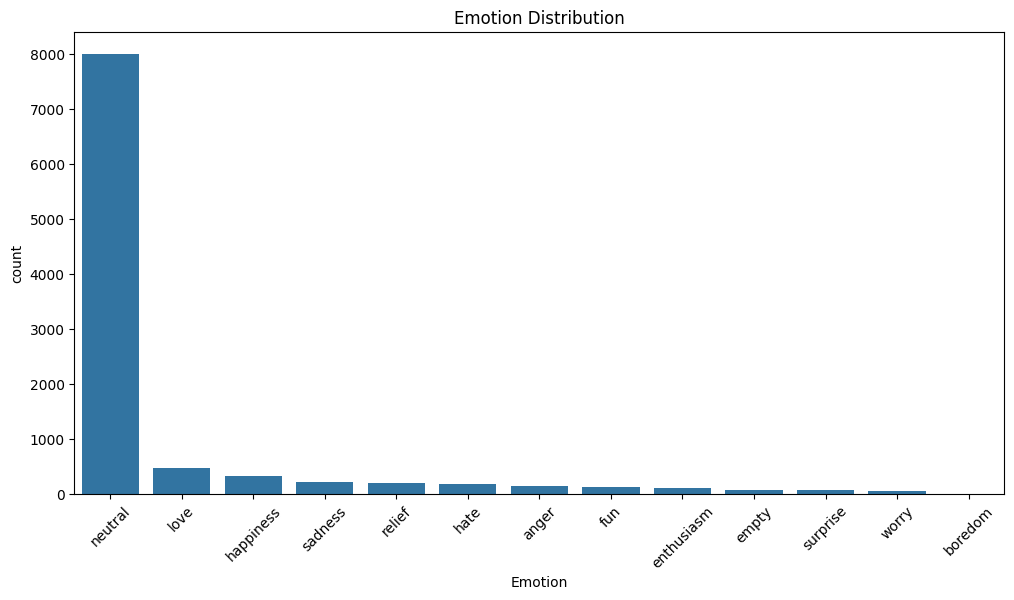

In [20]:
print("Dataset Shape:", df.shape)
print("Unique Emotions:", df['Emotion'].unique())

plt.figure(figsize=(12,6))
sns.countplot(data=df, x='Emotion', order=df['Emotion'].value_counts().index)
plt.xticks(rotation=45)
plt.title("Emotion Distribution")
plt.show()


In [21]:
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    # Lowercase
    text = text.lower()
    # Remove URLs, mentions, special characters, digits
    text = re.sub(r"http\S+|www\S+|https\S+", '', text, flags=re.MULTILINE)
    text = re.sub(r'\@\w+|\#','', text)
    text = re.sub(r'[^a-z\s]', '', text)
    # Remove stopwords
    tokens = text.split()
    tokens = [word for word in tokens if word not in stop_words]
    return " ".join(tokens)

df['clean_text'] = df['text'].apply(preprocess_text)
df[['text','clean_text','Emotion']].head()


,text,clean_text,Emotion
0,i do feel like i am alot more outgoing then i ...,feel like alot outgoing use though,neutral
1,i go back and face the home in that ruined sta...,go back face home ruined state feel even frust...,neutral
2,i feel the amount allocated is inadequate,feel amount allocated inadequate,neutral
3,im feeling very mellow and affectionate right now,im feeling mellow affectionate right,love
4,i feel their anticipation on the update and i ...,feel anticipation update eager get,enthusiasm


In [22]:
# Filter out emotion classes with fewer than 2 samples to avoid stratify errors
class_counts = df['Emotion'].value_counts()
valid_classes = class_counts[class_counts >= 2].index

df_filtered = df[df['Emotion'].isin(valid_classes)].reset_index(drop=True)

X = df_filtered['clean_text']
y = df_filtered['Emotion']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Train size: {len(X_train)}")
print(f"Test size: {len(X_test)}")
print("Emotion classes in training set:", y_train.nunique())
print("Emotion classes in testing set:", y_test.nunique())


Train size: 6999
Test size: 3000
Emotion classes in training set: 12
Emotion classes in testing set: 12


In [23]:
max_vocab_size = 10000
max_seq_len = 100

tokenizer = Tokenizer(num_words=max_vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_seq_len, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=max_seq_len, padding='post', truncating='post')


In [24]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

num_classes = len(le.classes_)
print("Classes:", le.classes_)


Classes: ['anger' 'empty' 'enthusiasm' 'fun' 'happiness' 'hate' 'love' 'neutral'
 'relief' 'sadness' 'surprise' 'worry']


In [25]:
embedding_dim = 128

model = Sequential([
    Embedding(input_dim=max_vocab_size, output_dim=embedding_dim),
    Bidirectional(LSTM(64)),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dense(num_classes, activation='softmax')
])

# Build the model by specifying input shape explicitly
model.build(input_shape=(None, max_seq_len))

model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 100, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 12)             │           780 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,387,852 (5.29 MB)

 Trainable params: 1,387,852 (5.29 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
history = model.fit(
    X_train_pad, y_train_enc,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)


Epoch 1/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 45s 345ms/step - accuracy: 0.7586 - loss: 1.3270 - val_accuracy: 0.8157 - val_loss: 0.8864
Epoch 2/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 25s 248ms/step - accuracy: 0.7977 - loss: 0.8560 - val_accuracy: 0.8486 - val_loss: 0.5708
Epoch 3/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 25s 253ms/step - accuracy: 0.8454 - loss: 0.4789 - val_accuracy: 0.8614 - val_loss: 0.4910
Epoch 4/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 41s 258ms/step - accuracy: 0.8774 - loss: 0.3712 - val_accuracy: 0.8700 - val_loss: 0.4952
Epoch 5/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 41s 252ms/step - accuracy: 0.9064 - loss: 0.2838 - val_accuracy: 0.8943 - val_loss: 0.4185
Epoch 6/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 41s 252ms/step - accuracy: 0.9315 - loss: 0.1948 - val_accuracy: 0.9300 - val_loss: 0.3645
Epoch 7/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 25s 253ms/step - accuracy: 0.9609 - loss: 0.1332 - val_accuracy: 0.9286 - val_loss: 0.3189
Epoch 8/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 41s 253ms/step - accuracy: 0.9757 - loss: 0.0917 - val_accu

94/94 - 3s - 30ms/step - accuracy: 0.9563 - loss: 0.2947
Test Accuracy: 0.9563
94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step
              precision    recall  f1-score   support

       anger       0.85      0.89      0.87        45
       empty       0.71      0.68      0.70        22
  enthusiasm       0.92      0.94      0.93        35
         fun       0.91      0.79      0.85        38
   happiness       0.97      0.89      0.93       100
        hate       0.83      0.88      0.85        56
        love       0.97      0.91      0.94       142
     neutral       0.98      0.98      0.98      2402
      relief       0.53      0.75      0.62        60
     sadness       0.98      0.91      0.94        64
    surprise       0.81      0.85      0.83        20
       worry       0.50      0.44      0.47        16

    accuracy                           0.96      3000
   macro avg       0.83      0.83      0.83      3000
weighted avg       0.96      0.96      0.96      3000



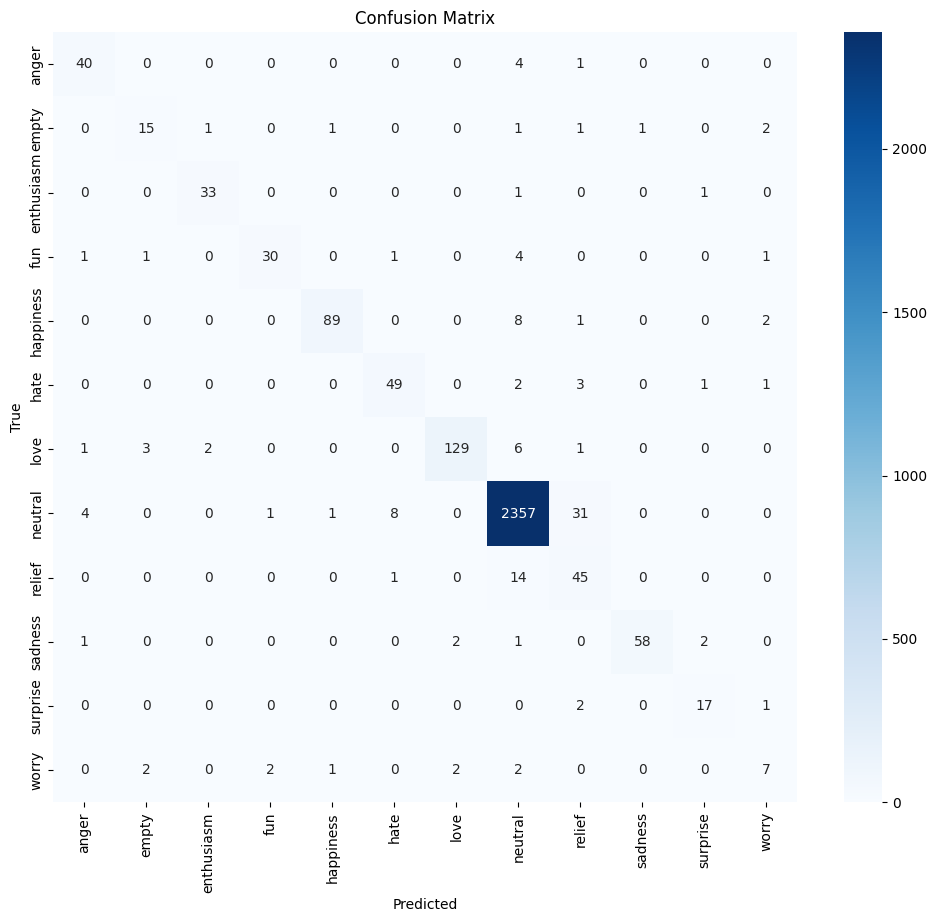

In [27]:
test_loss, test_acc = model.evaluate(X_test_pad, y_test_enc, verbose=2)
print(f"Test Accuracy: {test_acc:.4f}")

y_pred_probs = model.predict(X_test_pad)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(y_test_enc, y_pred, target_names=le.classes_))

# Confusion matrix
cm = confusion_matrix(y_test_enc, y_pred)

plt.figure(figsize=(12,10))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=le.classes_, yticklabels=le.classes_, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()


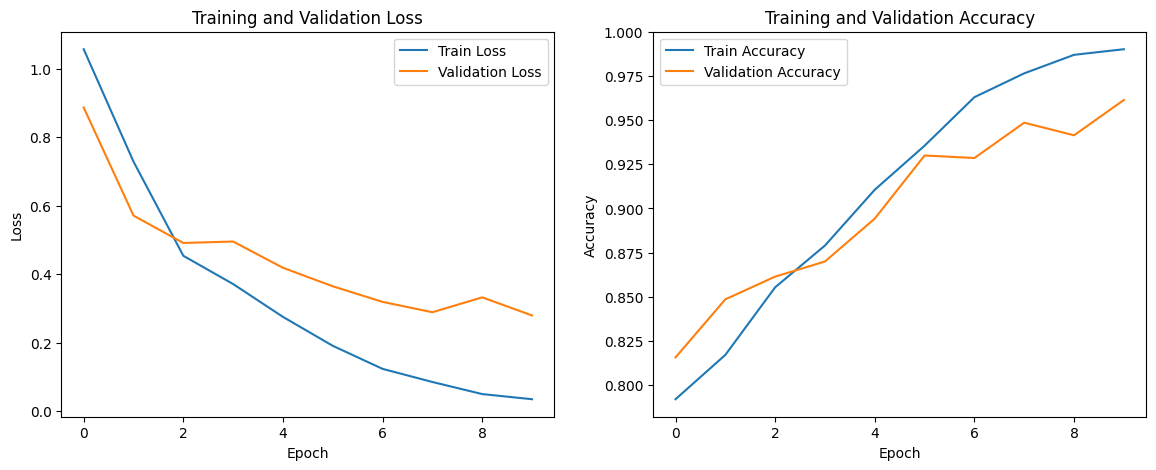

In [29]:
# Plot training and validation loss and accuracy curves

plt.figure(figsize=(14,5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()

plt.show()


In [34]:
def predict_emotion(text):
    processed = preprocess_text(text)
    seq = tokenizer.texts_to_sequences([processed])
    padded = pad_sequences(seq, maxlen=max_seq_len, padding='post')
    pred_prob = model.predict(padded)[0]
    pred_label = le.classes_[np.argmax(pred_prob)]
    confidence = np.max(pred_prob)
    return pred_label, confidence

def main():
    print("Enter text to predict emotion (type 'exit' to quit):")
    while True:
        text = input(">> ")
        if text.lower() == 'exit':
            print("Exiting...")
            break
        emotion, confidence = predict_emotion(text)
        print(f"Predicted Emotion: {emotion}, Confidence: {confidence:.2f}")

# Run CLI
if __name__ == "__main__":
    main()


Enter text to predict emotion (type 'exit' to quit):
>> i arrived at my destination re energized and feeling as though i had just had a long lovely conversation with a dear friend with whom i had not visited in a long time
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
Predicted Emotion: love, Confidence: 1.00
>> i guess made me feel pleasantly surprised
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
Predicted Emotion: surprise, Confidence: 0.66
>> i thought i was the only one who constantly lied deceived conned people for profit held no empathy or regard for other peoples safety heavily aggressive constantly feeling agitated or depressed narcissistant inability to maintain relationships and the inability to tolerate boredom in the world
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
Predicted Emotion: sadness, Confidence: 0.98
>> exit
Exiting...
